# 420 – Generator vs. Discriminator: a Toy Circuit

A **Generative Adversarial Network (GAN)** is a game between two players:

* the **generator** produces samples and wants them to look real;
* the **discriminator** inspects a sample and decides *real* or *fake*.

Training improves both until the generator's samples cannot be told apart from real data.
In a **quantum GAN (qGAN)** the generator is a quantum circuit.

This notebook is a **warm-up with no training at all**.  It builds the two roles from fixed
circuits so you can *see* them: a generator that writes a 4-bit pattern into qubits, and a
discriminator that checks whether the pattern equals the "real" one, `1011`.

**The QGAN series**

| Notebook | Topic |
|---|---|
| `420` | the generator / discriminator idea, with plain circuits (no training) |
| `421` | **a full qGAN**: learn a 1-D log-normal distribution |
| `422` | 2-D data with correlations – why entanglement matters |
| `423` | a real dataset (used-car prices) |
| `424` | application: price a financial option with a trained generator + amplitude estimation |
| `425` | experiments: what makes qGAN training stable? |

**Prerequisites:** basic gates and measurement (`001`–`004`), `combine`/`compose` (`003`).

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumRegister, QuantumCircuit, ClassicalRegister
from qiskit.visualization import plot_histogram

## The generator

The generator writes a bit pattern into 4 qubits `g0..g3`: an $X$ gate wherever the pattern
has a `1`.  The pattern string is read left to right as `g0 g1 g2 g3`, so `'0011'` sets
`g2` and `g3`.

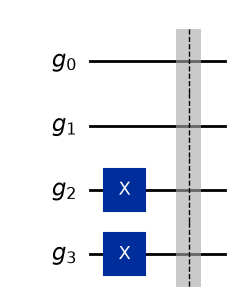

In [3]:
qr_generator = QuantumRegister(4, 'g')
qr_discriminator = QuantumRegister(4, 'd')
cr_measure = ClassicalRegister(4, 'm')

def make_generator(bit_pattern):
    circuit_generator = QuantumCircuit(qr_generator)
    for qubit, bit in enumerate(bit_pattern):
        if bit == '1':
            circuit_generator.x(qubit)
    circuit_generator.barrier()
    return circuit_generator

circuit_generator = make_generator('0011')
circuit_generator.draw(output='mpl')

## The discriminator

The discriminator knows the **real** pattern: `g0 g1 g2 g3 = 1 0 1 1`.  For each position it
copies "does this bit match?" into a detector qubit `d`:

* where the real bit is `1`, a CNOT copies the bit (`d = g`);
* where the real bit is `0`, an $X$ before the CNOT copies its inverse (`d = NOT g`).

So all four detectors read `1` **exactly when the pattern is real**.

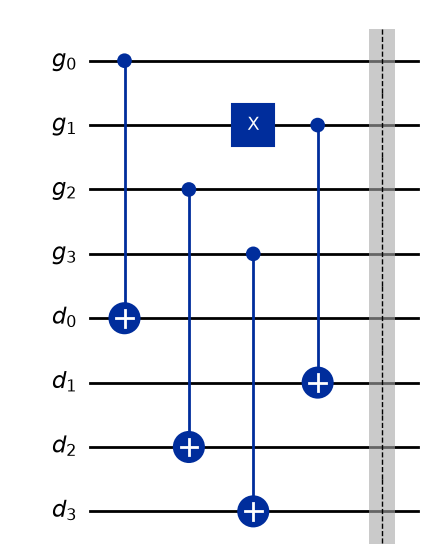

In [4]:
circuit_discriminator = QuantumCircuit(qr_generator, qr_discriminator)
# real pattern 1011: g0, g2, g3 must be 1 -> copy them with CNOTs
circuit_discriminator.cx(0, 4)
circuit_discriminator.cx(2, 6)
circuit_discriminator.cx(3, 7)
# g1 must be 0 -> invert it, then copy
circuit_discriminator.x(1)
circuit_discriminator.cx(1, 5)
circuit_discriminator.barrier()
circuit_discriminator.draw('mpl')

Finally we measure the four detector qubits.

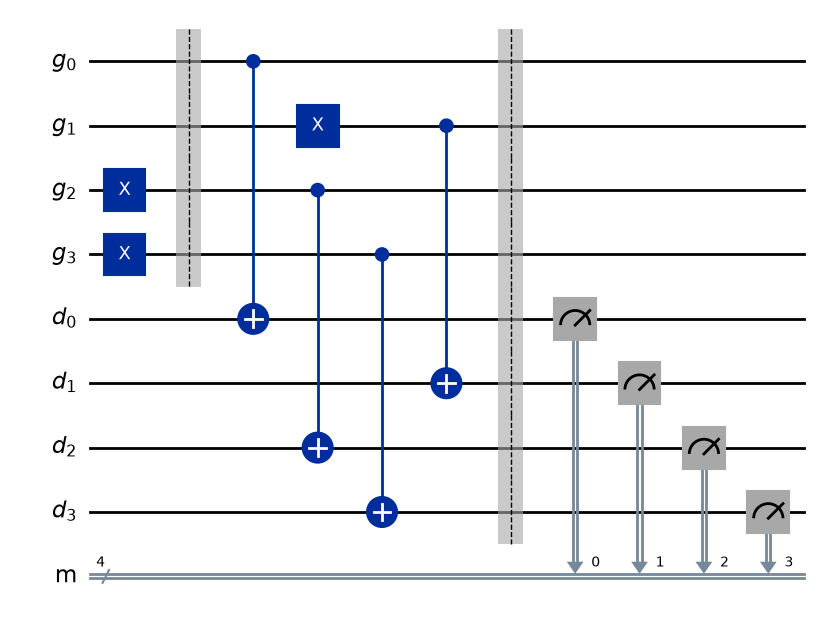

In [5]:
circuit_measure = QuantumCircuit(qr_discriminator, cr_measure)
circuit_measure.measure(qr_discriminator, cr_measure)

qc = combine(combine(circuit_generator, circuit_discriminator), circuit_measure)
qc.draw('mpl')

## Does the generator fool the discriminator?

The circuit is deterministic, so one shot is enough.  Qiskit prints classical bits right to
left (`m3 m2 m1 m0`); we reverse the string so it reads `d0 d1 d2 d3`.

detectors d0..d3: 0111 -> FAKE


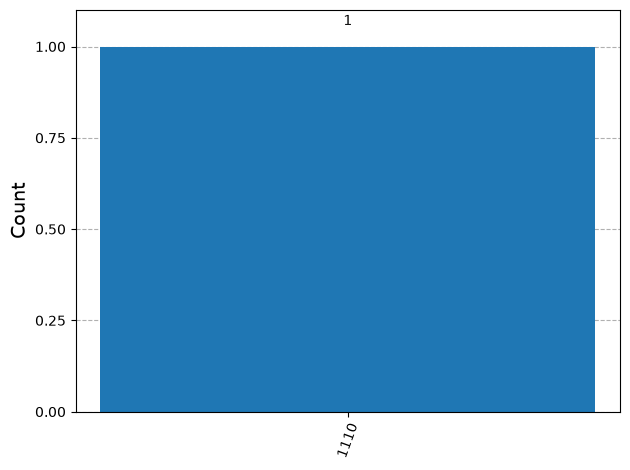

In [6]:
results = execute(qc, backend=backend, shots=1).result()
detectors = list(results.get_counts().keys())[0][::-1]
print("detectors d0..d3:", detectors, "->", "REAL" if detectors == "1111" else "FAKE")
plot_histogram(results.get_counts())

`0011` differs from `1011` in the first bit, so detector `d0` reads 0 and the sample is
rejected.

## The generator's task: search for a pattern that passes

A real GAN generator *learns* what passes.  Here we can simply try all 16 patterns and ask the
discriminator about each one – a brute-force stand-in for training.

In [7]:
def discriminator_says(pattern):
    circuit = combine(combine(make_generator(pattern), circuit_discriminator), circuit_measure)
    detectors = list(execute(circuit, backend=backend, shots=1).result().get_counts().keys())[0][::-1]
    return detectors

for i in range(16):
    pattern = format(i, '04b')
    detectors = discriminator_says(pattern)
    print(pattern, detectors, "<- REAL" if detectors == "1111" else "")

0000 0100 


0001 0101 


0010 0110 


0011 0111 


0100 0000 


0101 0001 


... (6 outputs left out)

1100 1000 


1101 1001 


1110 1010 


1111 1011 


## What changes in a real qGAN (`421`)

| This toy | A real qGAN |
|---|---|
| generator writes one fixed bit pattern | generator is a **parameterised** circuit whose measurement gives a whole **probability distribution** |
| discriminator is a fixed quantum check | discriminator is a small **classical neural network** that is *trained* |
| "training" = trying all 16 patterns | both players are trained by **gradient descent**, in turns |
| goal: hit one pattern | goal: reproduce the *distribution* of the training data |

## Try it yourself
1. Change the real pattern to `0110`: which gates of the discriminator must change?
2. Make the generator put `g0` into superposition with a Hadamard and run 1000 shots.  How
   often is it judged real?  *(This is the first step towards a generator that outputs
   probabilities.)*

**Next:** `421-QGAN-02-LogNormal-1D`.